# Remembering from a Fragment

*The Mathematics of Machine Intelligence · Chapter 6*

Let a few cues bring back a whole stored pattern, and see where the recall fails.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask what is stored, what the cue is, and how similar the stored items are. For a small network, work the vote, the storage sums and the energy by hand before running any simulation. For a retrieval question, compute shares from match scores at the setting actually used and say that a share is a weight, not a chance of being right. Check whether the intended item could be missing from the candidates, and whether two items share the details the cue contains.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 6, Remembering from a Fragment: executable mathematics and reader-facing teaching content."""
import math
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'
DIVERGING = LinearSegmentedColormap.from_list('mmi_diverging', [TERRA, '#ffffff', TEAL])

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def sgn(value):
    return '+1' if value > 0 else '-1'

def panels(ratios=None):
    kwargs = {'gridspec_kw': {'width_ratios': ratios}} if ratios else {}
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained', **kwargs)
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 11)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def update_unit(total_vote, current):
    """The chapter's vote rule: take the sign of the total; keep the current state on a tie."""
    if total_vote > 0:
        return 1
    if total_vote < 0:
        return -1
    return current

def storage_links(patterns):
    """w_ij = sum over stored patterns of xi_i xi_j, with no self-links."""
    patterns = np.asarray(patterns, dtype=float)
    links = patterns.T @ patterns
    np.fill_diagonal(links, 0.0)
    return links

def energy(links, state):
    state = np.asarray(state, dtype=float)
    return float(-0.5 * state @ links @ state)

def settle(links, state, rng, max_sweeps=50):
    """One-unit-at-a-time updates in random order until a full sweep changes nothing."""
    s = np.array(state, dtype=float)
    sweeps = 0
    for sweeps in range(1, max_sweeps + 1):
        changed = False
        for i in rng.permutation(len(s)):
            new = update_unit(links[i] @ s, s[i])
            if new != s[i]:
                s[i] = new
                changed = True
        if not changed:
            break
    return (s, sweeps)

def settle_trace(links, state, rng, max_sweeps=8):
    """Energy and overlap with the starting reference after every single-unit update."""
    s = np.array(state, dtype=float)
    energies, states = ([energy(links, s)], [s.copy()])
    for _ in range(max_sweeps):
        changed = False
        for i in rng.permutation(len(s)):
            new = update_unit(links[i] @ s, s[i])
            if new != s[i]:
                s[i] = new
                changed = True
            energies.append(energy(links, s))
            states.append(s.copy())
        if not changed:
            break
    return (np.array(energies), np.array(states))

def simultaneous_steps(links, state, steps):
    """Every unit updates at the same instant, using the previous state for all votes."""
    s = np.array(state, dtype=float)
    states = [s.copy()]
    for _ in range(steps):
        h = links @ s
        s = np.where(h > 0, 1.0, np.where(h < 0, -1.0, s))
        states.append(s.copy())
    return np.array(states)
NEIGHBOURS = np.array([1.0, 1.0, -1.0])

def vote_picture(third_link=1, current=1):
    links = np.array([1.0, 1.0, float(third_link)])
    votes = links * NEIGHBOURS
    total = float(votes.sum())
    new = update_unit(total, current)
    fig, ax = panels()
    names = ['neighbor A\n(+1, link 1)', 'neighbor B\n(+1, link 1)', f'neighbor C\n(-1, link {third_link:g})', 'total\nvote h']
    values = list(votes) + [total]
    colours = [TEAL if v > 0 else TERRA for v in votes] + [NAVY]
    bars = ax[0].bar(range(4), values, color=colours, width=0.6)
    ax[0].axhline(0, color=GREY, linewidth=1)
    for bar, v in zip(bars, values):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + (0.15 if v >= 0 else -0.15), sig(v), va='bottom' if v >= 0 else 'top')
    ax[0].set_xticks(range(4))
    ax[0].set_xticklabels(names, fontsize=9)
    ax[0].set(ylabel='vote (link x neighbor value)', title=f'The unit becomes {sgn(new)}', ylim=(-3.6, 3.6))
    grid = np.linspace(-1, 3, 81)
    ax[1].plot(grid, 2 - grid, color=NAVY, linewidth=2.5)
    ax[1].axhline(0, color=GREY, linewidth=1)
    ax[1].fill_between(grid, 0, 4, where=2 - grid > 0, color=TEAL, alpha=0.12)
    ax[1].fill_between(grid, -2, 0, where=2 - grid < 0, color=TERRA, alpha=0.12)
    ax[1].text(-0.8, 2.6, 'becomes +1', color=TEAL, fontsize=10)
    ax[1].text(2.15, -1.5, 'becomes -1', color=TERRA, fontsize=10)
    ax[1].annotate('tie: keeps its\ncurrent state', (2, 0), textcoords='offset points', xytext=(-8, 36), ha='center', fontsize=9, color=DARK_GOLD, arrowprops={'arrowstyle': '->', 'color': DARK_GOLD})
    ring(ax[1], third_link, total)
    ax[1].set(xlabel='link strength to neighbor C', ylabel='total vote h', title='Where the vote flips', xlim=(-1.1, 3.1), ylim=(-2, 4))
    if total == 0:
        outcome = f'stays {sgn(current)} (tie)'
    else:
        outcome = f'becomes {sgn(new)}'
    metrics = {'Votes for plus one': sig(votes[votes > 0].sum()), 'Votes for minus one': sig(votes[votes < 0].sum()), 'Total vote (h)': sig(total), 'The unit': outcome}
    if total == 0:
        summary = f'The votes for plus one and for minus one cancel, so h = 0 and the unit keeps its current value, {sgn(current)}. The rule needs a tie-break, and this is it.'
    else:
        summary = f"The three votes add to h = {sig(total)}. That is {('positive' if total > 0 else 'negative')}, so the unit becomes {sgn(new)}, whatever it held before."
    calc = f'h = 1 x (+1) + 1 x (+1) + {third_link:g} x (-1) = {sig(total)}. ' + ('h is not zero, so the new value is the sign of h.' if total != 0 else f'h is zero, so the unit keeps {sgn(current)}.')
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def stored_patterns():
    """Six patterns over ten units. Units 1 and 2 are set by hand: they agree in patterns 1 to 3,
    disagree in 4 and 5 and agree in 6, so the chapter's three-agree-one-disagree example holds after four."""
    rng = np.random.default_rng(1982)
    patterns = rng.choice([-1, 1], size=(6, 10))
    patterns[:, 0] = [1, 1, -1, 1, 1, -1]
    patterns[:, 1] = [1, 1, -1, -1, -1, -1]
    return patterns
PAIRS = [(0, 1), (0, 2), (3, 4)]
PAIR_LABELS = ['units 1 and 2', 'units 1 and 3', 'units 4 and 5']

def storage_picture(patterns_stored=4, pair=0):
    patterns = stored_patterns()[:patterns_stored]
    links = storage_links(patterns)
    i, j = PAIRS[pair]
    contributions = patterns[:, i] * patterns[:, j]
    link = int(contributions.sum())
    agree, disagree = (int((contributions > 0).sum()), int((contributions < 0).sum()))
    fig, ax = panels([1.05, 1])
    limit = max(1, int(np.abs(links).max()))
    image = ax[0].imshow(links, cmap=DIVERGING, vmin=-limit, vmax=limit)
    for a, b in ((i, j), (j, i)):
        ax[0].add_patch(plt.Rectangle((b - 0.5, a - 0.5), 1, 1, fill=False, edgecolor=NAVY, linewidth=2.5))
    ax[0].set_xticks(range(10))
    ax[0].set_xticklabels(range(1, 11), fontsize=9)
    ax[0].set_yticks(range(10))
    ax[0].set_yticklabels(range(1, 11), fontsize=9)
    ax[0].grid(False)
    ax[0].set(xlabel='unit', ylabel='unit', title=f'Link strengths after {patterns_stored} pattern' + ('' if patterns_stored == 1 else 's'))
    fig.colorbar(image, ax=ax[0], shrink=0.8, label='link strength')
    running = np.cumsum(contributions)
    x = np.arange(1, patterns_stored + 1)
    ax[1].bar(x, contributions, color=[TEAL if c > 0 else TERRA for c in contributions], width=0.55)
    ax[1].plot(x, running, color=NAVY, marker='o', linewidth=2, label='running total')
    ax[1].axhline(0, color=GREY, linewidth=1)
    ax[1].set_xticks(range(1, 7))
    ax[1].set(xlabel='stored pattern', ylabel='agree +1, disagree -1', title=f'{PAIR_LABELS[pair].capitalize()}: link {link}', xlim=(0.4, 6.6), ylim=(-3.2, 4.2))
    ax[1].legend(fontsize=9, loc='upper right')
    off_diagonal = links[~np.eye(10, dtype=bool)]
    metrics = {'Link between the pair': sig(link), 'Patterns where they agree': str(agree), 'Patterns where they disagree': str(disagree), 'Strongest link anywhere': sig(np.abs(off_diagonal).max())}
    summary = f"After {patterns_stored} stored pattern{('s' if patterns_stored != 1 else '')}, {PAIR_LABELS[pair]} agree in {agree} and disagree in {disagree}, so their link is {link}. Each pattern adds +1 for agreement or -1 for disagreement."
    terms = ' '.join((('+' if c > 0 else '-') + '1' for c in contributions))
    calc = f"Link = sum over patterns of (value of unit {i + 1}) x (value of unit {j + 1}) = {terms.replace(' ', ' ')}, which is {link}. Links are unnormalized sums and have no self-links (the diagonal is 0)."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
UNITS, PATTERNS = (30, 5)

@lru_cache(maxsize=None)
def completion_rates(damage, units=UNITS, patterns=PATTERNS, trials=300):
    """Fractions of seeded runs that end at the target, at another stored pattern or an opposite, or elsewhere."""
    rng = np.random.default_rng([6, 3, damage])
    exact = other = elsewhere = 0
    sweeps_total = 0
    for _ in range(trials):
        stored = rng.choice([-1.0, 1.0], size=(patterns, units))
        links = storage_links(stored)
        start = stored[0].copy()
        if damage:
            start[rng.choice(units, size=damage, replace=False)] *= -1
        final, sweeps = settle(links, start, rng)
        sweeps_total += sweeps
        if np.array_equal(final, stored[0]):
            exact += 1
        elif any((np.array_equal(final, sign * row) for row in stored for sign in (1.0, -1.0))):
            other += 1
        else:
            elsewhere += 1
    return (exact / trials, other / trials, elsewhere / trials, sweeps_total / trials)
COMPLETION_GRID = [0, 2, 4, 5, 6, 8, 10, 12, 15]

def completion_picture(wrong_units=5):
    exact, other, elsewhere, mean_sweeps = completion_rates(wrong_units)
    rng = np.random.default_rng([6, 3, 99, wrong_units])
    fig, ax = panels()
    lowest, longest = (1.0, 1)
    for _ in range(12):
        stored = rng.choice([-1.0, 1.0], size=(PATTERNS, UNITS))
        links = storage_links(stored)
        start = stored[0].copy()
        if wrong_units:
            start[rng.choice(UNITS, size=wrong_units, replace=False)] *= -1
        _, states = settle_trace(links, start, rng)
        overlap = states @ stored[0] / UNITS
        hit = overlap[-1] == 1.0
        ax[0].step(np.arange(len(overlap)) / UNITS, overlap, where='post', color=TEAL if hit else TERRA, linewidth=1.6, alpha=0.8)
        lowest, longest = (min(lowest, overlap.min()), max(longest, len(overlap)))
    ax[0].axhline(1, color=GREY, linestyle='dashed', linewidth=1)
    ax[0].text(0.02, 1.0, 'the stored pattern', color=GREY, fontsize=9, va='bottom')
    ax[0].set(xlabel='sweeps (30 single-unit updates each)', ylabel='agreement with stored pattern', title='12 runs: teal ends at the target', ylim=(min(0.0, lowest) - 0.1, 1.15))
    curve = [completion_rates(k)[0] for k in COMPLETION_GRID]
    ax[1].plot(COMPLETION_GRID, curve, color=NAVY, linewidth=2.5, marker='o', markersize=4, label='ends at the target')
    ax[1].plot(COMPLETION_GRID, [completion_rates(k)[1] for k in COMPLETION_GRID], color=GOLD, linewidth=1.8, linestyle='dashed', label='another stored pattern or an opposite')
    ax[1].plot(COMPLETION_GRID, [completion_rates(k)[2] for k in COMPLETION_GRID], color=TERRA, linewidth=1.8, linestyle='dotted', label='elsewhere (no stored meaning)')
    ring(ax[1], wrong_units, exact)
    ax[1].set(xlabel='units wrong in the starting pattern', ylabel='share of 300 runs', title='Recall worsens as the start strays', ylim=(-0.03, 1.05))
    ax[1].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1)
    metrics = {'Runs ending at the target': f'{100 * exact:.0f} percent', 'Runs ending at another stored pattern or an opposite': f'{100 * other:.0f} percent', 'Runs ending in no stored pattern': f'{100 * elsewhere:.0f} percent', 'Average sweeps to settle': sig(mean_sweeps)}
    summary = f'Starting {wrong_units} units from a stored pattern in a network of {UNITS} units holding {PATTERNS} random patterns, {100 * exact:.0f} percent of 300 seeded runs ended exactly at it. Wrong answers were stable too: {100 * other:.0f} percent landed on another stored pattern or an opposite and {100 * elsewhere:.0f} percent on a state with no stored meaning.'
    calc = f'Each run draws {PATTERNS} random plus/minus-one patterns on {UNITS} units, builds the links by the storage rule, flips {wrong_units} units of pattern 1 at random and updates one unit at a time in random order until a full sweep changes nothing. Counts: {round(exact * 300)} at the target, {round(other * 300)} at another stored pattern or an opposite, {round(elsewhere * 300)} elsewhere, out of 300.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def start_state(links_seed_units, index):
    rng = np.random.default_rng([6, 4, index])
    return rng.choice([-1.0, 1.0], size=links_seed_units)

def energy_network():
    rng = np.random.default_rng([6, 4, 0])
    stored = rng.choice([-1.0, 1.0], size=(PATTERNS, UNITS))
    return (stored, storage_links(stored))

def two_unit_trace(schedule, steps=6):
    """The chapter's pair: positive link of 1, start opposite (plus, minus). Returns states and energies."""
    links = np.array([[0.0, 1.0], [1.0, 0.0]])
    s = np.array([1.0, -1.0])
    states = [s.copy()]
    for step in range(steps):
        if schedule == 'all at once':
            h = links @ s
            s = np.where(h > 0, 1.0, np.where(h < 0, -1.0, s))
        else:
            i = step % 2
            s = s.copy()
            s[i] = update_unit(links[i] @ s, s[i])
        states.append(s.copy())
    return (np.array(states), np.array([energy(links, row) for row in states]))
SCHEDULES = ['one at a time', 'all at once']

def energy_picture(schedule='one at a time', start=1):
    _, links = energy_network()
    s0 = start_state(UNITS, start)
    fig, ax = panels()
    if schedule == 'one at a time':
        energies, _ = settle_trace(links, s0, np.random.default_rng([6, 4, 50, start]), max_sweeps=6)
        x = np.arange(len(energies)) / UNITS
        ax[0].step(x, energies, where='post', color=NAVY, linewidth=2.2)
        ax[0].set(xlabel='sweeps (each sweep is 30 single-unit updates)', ylabel='energy E', title='One at a time: energy only falls')
        largest_rise = float(np.max(np.diff(energies))) if len(energies) > 1 else 0.0
        end_text = 'a stable state'
        first, last = (energies[0], energies[-1])
        steps = len(energies) - 1
    else:
        states = simultaneous_steps(links, s0, 12)
        energies = np.array([energy(links, row) for row in states])
        ax[0].plot(np.arange(len(energies)), energies, color=TERRA, linewidth=2.2, marker='o', markersize=4)
        ax[0].set(xlabel='steps (all 30 units update together)', ylabel='energy E', title='All at once: no guarantee')
        largest_rise = float(np.max(np.diff(energies)))
        if np.array_equal(states[-1], states[-2]):
            end_text = 'a stable state'
        elif np.array_equal(states[-1], states[-3]):
            end_text = 'a back-and-forth cycle of two states'
        else:
            end_text = 'still changing after 12 steps'
        first, last = (energies[0], energies[-1])
        steps = len(energies) - 1
    pair_colours = {'one at a time': TEAL, 'all at once': TERRA}
    for name, style in (('one at a time', 'solid'), ('all at once', 'dashed')):
        states2, energies2 = two_unit_trace(name)
        chosen = name == schedule
        ax[1].plot(np.arange(len(energies2)), energies2, color=pair_colours[name], linewidth=3 if chosen else 1.6, linestyle=style, marker='o', markersize=6 if chosen else 4, label=name)
    ax[1].set_yticks([-1, 1])
    ax[1].set_yticklabels(['same (-1)', 'opposite (+1)'])
    ax[1].set(xlabel='step', ylabel='energy of the two-unit pair', title='Two units that start opposite', ylim=(-1.6, 1.6))
    ax[1].legend(fontsize=9, loc='center right')
    metrics = {'Energy at the start': sig(first), 'Energy at the end': sig(last), 'Largest rise in one step': sig(largest_rise), 'The run ends in': end_text}
    if schedule == 'one at a time':
        summary = f'Updating one unit at a time from random start {start}, the energy fell from {sig(first)} to {sig(last)} and never rose; the largest rise was {sig(largest_rise)}. The two-unit pair on the right settles after one change.'
    else:
        summary = f'With all units updating together from random start {start}, energy went from {sig(first)} to {sig(last)}, and the run ends in {end_text}. The pair on the right swaps places forever and stays at energy +1.'
    calc = 'Energy E = -1/2 x sum over i and j of w_ij s_i s_j. For two units joined by a link of 1: matching states give E = -1 and opposite states give E = +1. Updated one at a time from (+1, -1), the first unit sees a vote of -1, becomes -1, and the pair matches with E = -1. Updated together, each copies the other: (+1, -1) becomes (-1, +1) and then back, with E = +1 every step.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
CAPACITY_UNITS = [50, 100, 200]
CAPACITY_LOADS = [2, 5, 10, 15, 20, 30, 40]

@lru_cache(maxsize=None)
def capacity_runs(units, stored, trials=30):
    """Wrong units left after settling when the start is exactly a stored pattern."""
    rng = np.random.default_rng([6, 5, units, stored])
    wrong = []
    for _ in range(trials):
        patterns = rng.choice([-1.0, 1.0], size=(stored, units))
        links = storage_links(patterns)
        final, _ = settle(links, patterns[0], rng, max_sweeps=30)
        wrong.append(int(np.sum(final != patterns[0])))
    return tuple(wrong)

def crosstalk_error_rate(units, stored):
    """Chance a unit's first vote is wrong when the network sits on a stored pattern (Gaussian crosstalk estimate)."""
    if stored < 2:
        return 0.0
    z = math.sqrt((units - 1) / (stored - 1))
    return 0.5 * math.erfc(z / math.sqrt(2))

def capacity_picture(units=100, stored=10):
    wrong = np.array(capacity_runs(units, stored))
    fig, ax = panels()
    for n, style, colour in [(50, 'dotted', GREY), (100, 'solid', TEAL), (200, 'dashed', TERRA)]:
        chosen = n == units
        curve = [np.mean(capacity_runs(n, p)) / n * 100 for p in CAPACITY_LOADS]
        ax[0].plot(CAPACITY_LOADS, curve, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, marker='o', markersize=4, label=f'{n} units')
        ax[0].axvline(0.15 * n, color=colour, linewidth=0.9, linestyle='dotted', alpha=0.6)
    ring(ax[0], stored, np.mean(wrong) / units * 100)
    ax[0].set(xlabel='stored patterns', ylabel='units wrong at the end (percent)', title='Recall fails as memories crowd in')
    ax[0].legend(fontsize=9, loc='upper left')
    top = int(max(wrong.max(), 5)) + 2
    counts = np.bincount(wrong, minlength=top + 1)
    ax[1].bar(range(len(counts)), counts, color=[TEAL if k < 5 else TERRA for k in range(len(counts))], width=0.8)
    ax[1].axvline(4.5, color=GREY, linestyle='dashed', linewidth=1)
    ax[1].text(4.6, ax[1].get_ylim()[1] * 0.92, 'fewer than 5 wrong', fontsize=9, color=GREY, ha='left', va='top')
    ax[1].set(xlabel='units wrong at the end', ylabel='runs (of 30)', title=f'{units} units, {stored} patterns')
    few = int(np.sum(wrong < 5))
    stayed = int(np.sum(wrong == 0))
    metrics = {'Average units wrong at the end': sig(wrong.mean()), 'Runs with fewer than 5 units wrong': f'{few} of 30', 'Runs that stayed exactly at the start': f'{stayed} of 30', 'Share of units wrong after one simultaneous pass (estimate)': f'{100 * crosstalk_error_rate(units, stored):.2g} percent'}
    summary = f"With {units} units and {stored} random patterns, 30 seeded runs started at a stored pattern and ended with {sig(wrong.mean())} units wrong on average; {few} of 30 had fewer than 5 wrong. The dotted verticals mark 0.15 N, Hopfield's rule of thumb quoted in the chapter."
    calc = f"Crosstalk estimate: each unit's vote is (N - 1) from its own pattern plus noise of size sqrt((P - 1)(N - 1)). A first-pass error needs the noise to beat the signal: chance = Phi(-sqrt((N - 1)/(P - 1))) = Phi(-sqrt({units - 1}/{max(stored - 1, 1)})) = {crosstalk_error_rate(units, stored):.3g}. The runs use the plus/minus-one storage rule and one-at-a-time updates."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def softmax(scores, beta):
    z = beta * np.asarray(scores, dtype=float)
    z = z - z.max()
    e = np.exp(z)
    return e / e.sum()

def softmax_picture(beta=1, second_score=2):
    scores = np.array([3.0, float(second_score)])
    shares = softmax(scores, beta)
    fig, ax = panels()
    bars = ax[0].bar(['record 1\n(score 3)', f'record 2\n(score {second_score:g})'], shares, color=[TEAL, TERRA], width=0.55)
    for bar, v in zip(bars, shares):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 0.02, sig(v), va='bottom')
    ax[0].set(ylabel='share of the say (p)', title=f'Sharpness (beta) = {beta:g}', ylim=(0, 1.15))
    grid = np.geomspace(0.25, 10, 120)
    for other, style, colour in [(1, 'dotted', GREY), (2, 'solid', TEAL), (2.5, 'dashed', GOLD), (3, 'dashdot', TERRA)]:
        chosen = other == second_score
        ax[1].plot(grid, [softmax([3.0, float(other)], b)[0] for b in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'other score {other:g}')
    ring(ax[1], beta, shares[0])
    ax[1].set_xscale('log')
    ax[1].set_xticks([0.25, 0.5, 1, 2, 5, 10])
    ax[1].set_xticklabels(['0.25', '0.5', '1', '2', '5', '10'])
    ax[1].set(xlabel='sharpness (beta)', ylabel='share for record 1', title='Turning the dial up', ylim=(0.45, 1.03))
    ax[1].legend(fontsize=9, loc='lower right')
    metrics = {'Share for record 1': sig(shares[0]), 'Share for record 2': sig(shares[1]), 'Score gap': sig(3 - second_score), 'Shares add up to': sig(shares.sum())}
    if second_score == 3:
        summary = 'The two scores tie, so each record gets half at every setting of the dial. The dial changes nothing when there is no best match.'
    else:
        summary = f'With scores 3 and {second_score:g} and beta {beta:g}, record 1 gets {sig(shares[0])} of the say. Nothing about the scores changed, only the dial, and this share is a weight, not the chance that record 1 is right.'
    calc = f'p1 = e^({beta:g} x 3) / (e^({beta:g} x 3) + e^({beta:g} x {second_score:g})) = 1 / (1 + e^(-{beta:g} x {sig(3 - second_score)})) = {sig(shares[0])}. p2 = 1 - p1 = {sig(shares[1])}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
RETRIEVAL_UNITS, RETRIEVAL_PATTERNS, QUERY_WRONG = (32, 8, 8)

def retrieval_patterns(crowding, rng):
    if crowding == 'similar patterns':
        base = rng.choice([-1.0, 1.0], size=RETRIEVAL_UNITS)
        stored = np.tile(base, (RETRIEVAL_PATTERNS, 1))
        for row in stored:
            row[rng.choice(RETRIEVAL_UNITS, size=6, replace=False)] *= -1
        return stored
    return rng.choice([-1.0, 1.0], size=(RETRIEVAL_PATTERNS, RETRIEVAL_UNITS))

def attention_update(stored, query, beta):
    """Modern Hopfield step: shares from softmax of the match scores, new state is the shares-weighted average.
    This is attention with query = current state and keys = values = stored patterns."""
    scores = stored @ query
    shares = softmax(scores, beta)
    return (shares @ stored, shares)

@lru_cache(maxsize=None)
def retrieval_errors(beta, crowding, runs=200):
    rng = np.random.default_rng([6, 7, 1 if crowding == 'similar patterns' else 0])
    modern = classical = 0.0
    for _ in range(runs):
        stored = retrieval_patterns(crowding, rng)
        query = stored[0].copy()
        query[rng.choice(RETRIEVAL_UNITS, size=QUERY_WRONG, replace=False)] *= -1
        new, _ = attention_update(stored, query, beta)
        modern += np.sum(np.where(new > 0, 1.0, -1.0) != stored[0])
        links = storage_links(stored)
        h = links @ query
        after = np.where(h > 0, 1.0, np.where(h < 0, -1.0, query))
        classical += np.sum(after != stored[0])
    return (modern / runs, classical / runs)
RETRIEVAL_BETAS = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
CROWDINGS = ['random patterns', 'similar patterns']

def retrieval_picture(beta=0.1, crowding='random patterns'):
    rng = np.random.default_rng([6, 7, 77])
    stored = retrieval_patterns(crowding, rng)
    query = stored[0].copy()
    query[rng.choice(RETRIEVAL_UNITS, size=QUERY_WRONG, replace=False)] *= -1
    new, shares = attention_update(stored, query, beta)
    modern, classical = retrieval_errors(beta, crowding)
    fig, ax = panels()
    colours = [TEAL] + [GREY] * (RETRIEVAL_PATTERNS - 1)
    ax[0].bar(np.arange(1, RETRIEVAL_PATTERNS + 1), shares, color=colours, width=0.65)
    ax[0].set_xticks(range(1, RETRIEVAL_PATTERNS + 1))
    ax[0].set(xlabel='stored pattern (1 is the one to recall)', ylabel='share of the say', title='Shares for one example cue', ylim=(0, 1.05))
    grid = np.array(sorted(set(np.round(np.geomspace(0.01, 3, 40), 6)) | set(RETRIEVAL_BETAS)))
    for name, style, colour in [('random patterns', 'solid', TEAL), ('similar patterns', 'dashed', TERRA)]:
        chosen = name == crowding
        ax[1].plot(grid, [retrieval_errors(round(float(b), 6), name)[0] for b in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'{name}: attention step')
        ax[1].axhline(retrieval_errors(0.1, name)[1], color=colour, linestyle='dotted', linewidth=1.6, alpha=0.9, label=f'{name}: classical vote')
    ring(ax[1], beta, modern)
    ax[1].set_xscale('log')
    ax[1].set_xticks([0.01, 0.1, 1])
    ax[1].set_xticklabels(['0.01', '0.1', '1'])
    ax[1].axvline(1 / math.sqrt(RETRIEVAL_UNITS), color=GREY, linewidth=0.9, linestyle='dashed')
    ax[1].text(1 / math.sqrt(RETRIEVAL_UNITS) * 1.05, ax[1].get_ylim()[1] * 0.97, '1/sqrt(32)', fontsize=8, color=GREY, va='top')
    ax[1].set(xlabel='sharpness (beta)', ylabel='units wrong after one update', title='Sharper dial, fewer wrong units')
    ax[1].legend(fontsize=7, loc='upper right', bbox_to_anchor=(1.0, 0.9))
    metrics = {'Share on the stored pattern (this cue)': sig(shares[0]), 'Wrong units after one attention step (200 cues)': sig(modern), 'Wrong units after one classical vote step (200 cues)': sig(classical), 'Wrong units in the cue': str(QUERY_WRONG)}
    summary = f'For {crowding}, 32 units and 8 stored patterns, a cue with {QUERY_WRONG} units wrong gives the right pattern a share of {sig(shares[0])} at beta {beta:g}. One attention step leaves {sig(modern)} units wrong on average and one classical vote step leaves {sig(classical)}.'
    calc = 'Match score z_k = (stored pattern k) . (cue), entry by entry and summed. Shares p_k = e^(beta z_k) / sum of e^(beta z_m). New state = sum of p_k x (stored pattern k), then each entry is read by its sign. The right-hand averages use 200 seeded cues per setting; the dotted horizontal lines are the classical vote step for each kind of pattern. In a transformer, beta is fixed at 1/sqrt(d_k), here about 0.18.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
CHANCE = 25.0
REPORTED = {'knockout': (66.4, 44.6), 'control': (65.9, 58.8)}

def preference_kept(baseline, fragment):
    """Share of the above-chance occupancy that remains: (fragment - 25) / (baseline - 25)."""
    if baseline <= CHANCE:
        raise ValueError('The baseline occupancy must be above the 25 percent chance level.')
    return (fragment - CHANCE) / (baseline - CHANCE)

def occupancy_picture(fragment=44.6, baseline=66.4):
    kept = preference_kept(baseline, fragment)
    fig, ax = panels()
    labels = ['knockout\nall cues', 'knockout\nthree cues gone', 'control\nall cues', 'control\nthree cues gone']
    reported = [66.4, 44.6, 65.9, 58.8]
    bars = ax[0].bar(range(4), reported, color=[TEAL, TEAL, GOLD, GOLD], alpha=0.85, width=0.62)
    for k in (1, 3):
        bars[k].set_hatch('//')
    for bar, v in zip(bars, reported):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 1.0, f'{v:g}', va='bottom', fontsize=10)
    ax[0].axhline(CHANCE, color=GREY, linestyle='dashed', linewidth=1.2, label='equal occupancy (25)')
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, 1.0))
    ax[0].set_xticks(range(4))
    ax[0].set_xticklabels(labels, fontsize=8)
    ax[0].set(ylabel='time in target quadrant (percent)', title='The reported values', ylim=(0, 92))
    shares_kept = [100 * preference_kept(66.4, 44.6), 100 * preference_kept(65.9, 58.8), 100 * kept]
    names = ['knockout\n(reported)', 'control\n(reported)', 'your setting']
    bars2 = ax[1].bar(range(3), shares_kept, color=[TEAL, GOLD, NAVY], width=0.55)
    for bar, v in zip(bars2, shares_kept):
        tag(ax[1], bar.get_x() + bar.get_width() / 2, v + 2, f'{v:.0f}', va='bottom', fontsize=10)
    ax[1].axhline(100, color=GREY, linestyle='dotted', linewidth=1)
    ax[1].set_xticks(range(3))
    ax[1].set_xticklabels(names, fontsize=9)
    ax[1].set(ylabel='above-chance preference kept (percent)', title='Share of the preference kept', ylim=(0, 122))
    metrics = {'Occupancy with all cues': f'{baseline:g} percent', 'Occupancy with the fragment': f'{fragment:g} percent', 'Above-chance preference, all cues to fragment': f'{baseline - CHANCE:.1f} to {fragment - CHANCE:.1f} points', 'Share of that preference kept': f'{100 * kept:.0f} percent'}
    summary = f"Starting from {baseline:g} percent, an occupancy of {fragment:g} percent keeps {100 * kept:.0f} percent of the preference above the 25 percent equal-occupancy level. The two reported results keep about 47 percent (knockout mice) and 83 percent (controls); the share kept is this companion's own ratio, not a statistic from the study."
    calc = f'Share kept = ({fragment:g} - 25) / ({baseline:g} - 25) = {fragment - CHANCE:.1f} / {baseline - CHANCE:.1f} = {kept:.3f}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C06-D01: How does one unit decide by a vote?

A unit hears three neighbors, two saying plus one and one saying minus one. What does it do, and what does it do when the votes cancel?

Every other unit says plus or minus, and each voice counts for more or less according to its link. The unit adds up the votes and takes the sign of the total. If the total is exactly zero it keeps its current value. Repeated across the network, these small decisions can pull a damaged pattern toward a stored one.

$$
s_i \leftarrow \begin{cases}\operatorname{sign}(h_i), & h_i\ne 0,\\ s_i, & h_i=0,\end{cases}\qquad h_i=\sum_j w_{ij}\,s_j
$$

**Symbols:** s_i: the value of unit i, plus 1 or minus 1; h_i: the total vote unit i hears; w_ij: the link strength between unit i and unit j; sign: plus 1 for a positive total, minus 1 for a negative one

**Predict before looking:** With neighbors A and B at plus one through links of 1, predict the link strength on minus-one neighbor C at which the unit stops being pulled to plus one, and what it does exactly there.

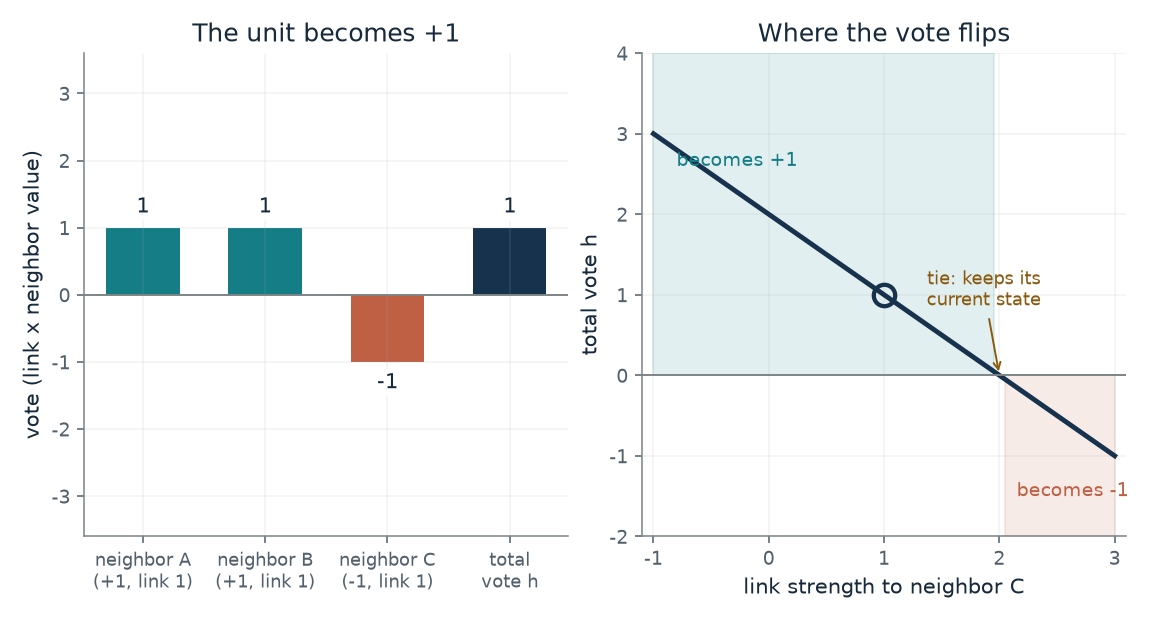

- **Votes for plus one:** 2
- **Votes for minus one:** -1
- **Total vote (h):** 1
- **The unit:** becomes +1

The three votes add to h = 1. That is positive, so the unit becomes +1, whatever it held before.

h = 1 x (+1) + 1 x (+1) + 1 x (-1) = 1. h is not zero, so the new value is the sign of h.

In [2]:
figure, values, explanation = vote_picture(**{'third_link': 1, 'current': 1})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How does one unit decide by a vote?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Link strength to the minus-one neighbor = 2, The unit's current value = -1: At link 2 the minus vote exactly cancels the two plus votes, so h = 0 and the unit keeps whatever it held, here minus one. Any weaker link and it turns plus one; any stronger and it turns minus one.

**Takeaway:** Each unit follows the side that wins its vote, and a tie leaves it as it was.

**Why it matters:** Everything else in the chapter is built from this one local rule: each unit adds up weighted votes and follows the sign.

**In brains and behavior:** Hopfield's paper reports no brain experiment, and the chapter treats this as a model, not a description of neurons.

**In machines:** The rule specifies a computation a machine performs: a weighted sum and a threshold at each unit.

**Where it applies:** Two-state units, a known set of links, and a unit that is picked to update. The rule is one local decision; whether many such decisions finish a pattern depends on the links and the update order.

**Check your understanding:** Two neighbors are plus one and one is minus one, all links 1 (as in the chapter). If one of the plus neighbors instead becomes minus one, what does the unit do?

<details><summary>Show the answer</summary>

The votes become -1, +1 and -1 with total h = -1. The total is negative, so the unit becomes minus one.

</details>

*Source: Chapter 6, A vote at each unit finished a damaged pattern. Book formula. The neighbor values (plus, plus, minus) and links of 1 are the chapter's Figure 6.1 illustration; the third link strength is varied here. The plus-or-minus-one form is a modern restatement of Hopfield's 0/1 units.*

## C06-D02: How do stored patterns become links?

Two units agree in three stored patterns and disagree in one. How strong is the link between them, and what does one more pattern do?

For each stored pattern, multiply the values of two units and add those products over all the patterns. Two units that agree across many memories end with a strong positive link. Two that disagree more often than they agree end with a negative one.

$$
w_{ij}=\sum_{\mu=1}^{P}\xi_i^{\mu}\xi_j^{\mu}\quad(i\ne j),\qquad w_{ii}=0
$$

**Symbols:** xi_i^mu: the value, plus or minus 1, of unit i in stored pattern mu; P: the number of stored patterns; w_ij: the link between units i and j; w_ii = 0: no unit links to itself

**Predict before looking:** Units 1 and 2 agree in three stored patterns and disagree in one. Predict their link, then predict what one more pattern in which they disagree does.

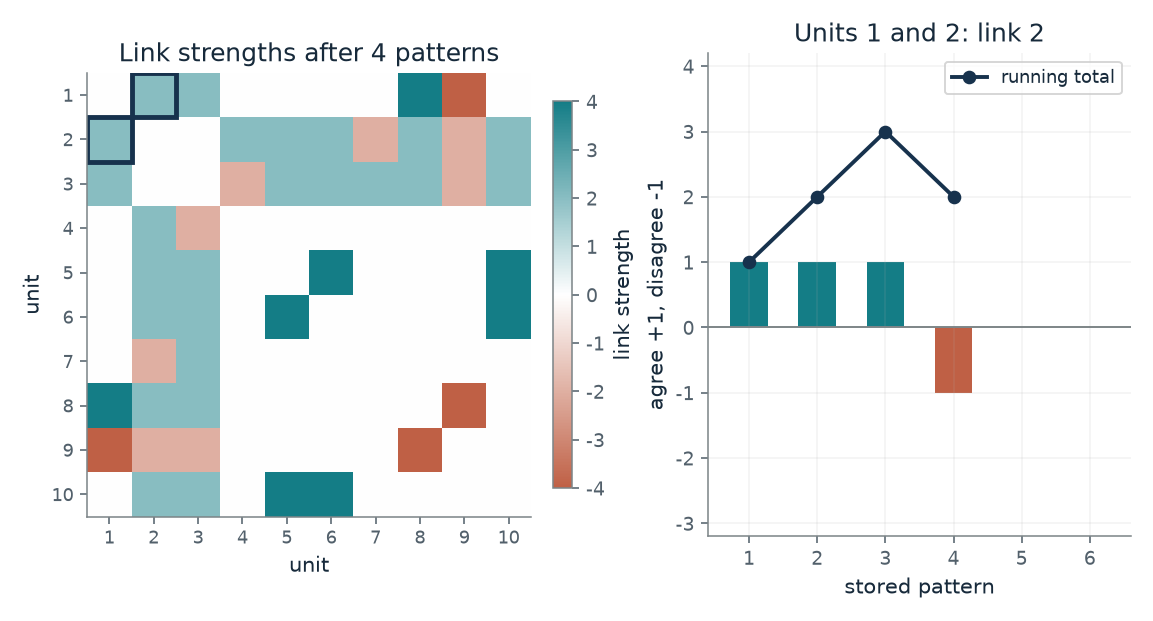

- **Link between the pair:** 2
- **Patterns where they agree:** 3
- **Patterns where they disagree:** 1
- **Strongest link anywhere:** 4

After 4 stored patterns, units 1 and 2 agree in 3 and disagree in 1, so their link is 2. Each pattern adds +1 for agreement or -1 for disagreement.

Link = sum over patterns of (value of unit 1) x (value of unit 2) = +1 +1 +1 -1, which is 2. Links are unnormalized sums and have no self-links (the diagonal is 0).

In [3]:
figure, values, explanation = storage_picture(**{'patterns_stored': 4, 'pair': 0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How do stored patterns become links?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Stored patterns = 5, Pair of units = 0: After four patterns the link between units 1 and 2 is 1 + 1 + 1 - 1 = 2. The fifth pattern has them disagree, so it drops to 1. Agreement adds and disagreement subtracts, one pattern at a time.

**Takeaway:** A link is a running tally of how often two units agree across the stored patterns.

**Why it matters:** Storage is a single pass with no training loop: add up products. It also means every stored pattern touches every link, which is the root of the crowding problem in the next illustrations.

**In brains and behavior:** The chapter treats the rule as a model of association; it says nothing about where a brain stores anything.

**In machines:** The links are computed in one pass from the patterns, which is why a classical Hopfield network needs no training loop.

**Where it applies:** Plus or minus one patterns, an unnormalized sum, and no self-links. Normalizing changes the scale of the votes but not their signs.

**Check your understanding:** Two units agree in four of five stored patterns and disagree in one. What is their link, and does a unit at plus one push the other toward plus one or minus one?

<details><summary>Show the answer</summary>

The link is 4 - 1 = 3, which is positive. A unit at plus one therefore casts a positive vote, pushing the other toward plus one.

</details>

*Source: Chapter 6, A vote at each unit finished a damaged pattern. Book formula. The ten-unit patterns are constructed for the illustration (seed 1982 for units 3 to 10); the first two units are set by hand so they agree in three of the first four patterns, as in the chapter's constructed example. Not Hopfield's data.*

## C06-D03: How far from a stored pattern can the start be?

If a pattern is damaged in a few units and the network updates, how often does it finish the pattern?

Start the network on a damaged pattern and let the units update one at a time. When the start is close, it usually settles on the stored pattern. The farther the start, the less often, and some runs end on a different stored pattern, on an opposite, or on a stable state with no stored meaning.

$$
s_i \leftarrow \operatorname{sign}\Bigl(\sum_{j} w_{ij}\,s_j\Bigr),\qquad w_{ij}=\sum_{\mu=1}^{P}\xi_i^{\mu}\xi_j^{\mu}
$$

**Symbols:** s: the state of all 30 units, plus or minus 1; w_ij: the storage-rule links for 5 random patterns; xi^mu: stored pattern mu

**Predict before looking:** Before moving the slider, predict how many wrong units in the starting pattern this 30-unit, 5-pattern network can tolerate before recall usually fails.

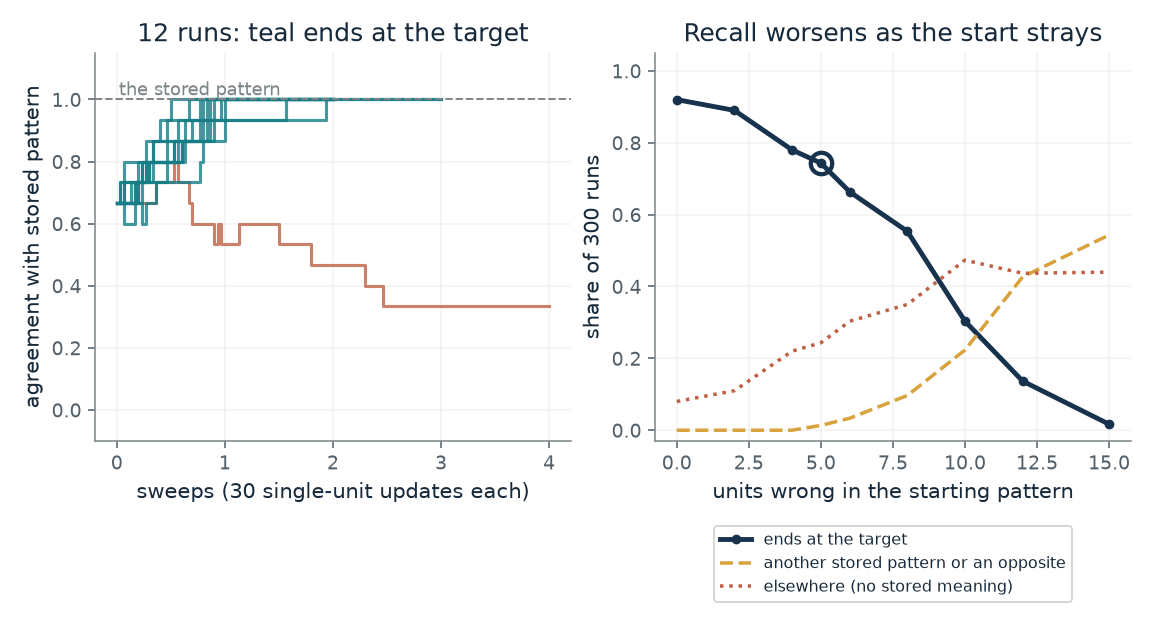

- **Runs ending at the target:** 74 percent
- **Runs ending at another stored pattern or an opposite:** 1 percent
- **Runs ending in no stored pattern:** 24 percent
- **Average sweeps to settle:** 2.28

Starting 5 units from a stored pattern in a network of 30 units holding 5 random patterns, 74 percent of 300 seeded runs ended exactly at it. Wrong answers were stable too: 1 percent landed on another stored pattern or an opposite and 24 percent on a state with no stored meaning.

Each run draws 5 random plus/minus-one patterns on 30 units, builds the links by the storage rule, flips 5 units of pattern 1 at random and updates one unit at a time in random order until a full sweep changes nothing. Counts: 223 at the target, 4 at another stored pattern or an opposite, 73 elsewhere, out of 300.

In [4]:
figure, values, explanation = completion_picture(**{'wrong_units': 5})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How far from a stored pattern can the start be?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Units wrong in the starting pattern (of 30) = 10: Around 10 wrong units out of 30 is where recall of the exact target stops being usual. Wrong answers are stable too: runs end on other stored patterns, opposites, or states with no stored meaning.

**Takeaway:** A close cue is usually finished, a far one is not, and the network gives no warning when it settles on a wrong answer.

**Why it matters:** This is the content-addressable memory Hopfield wished for: a piece of an item leads to the rest. It also shows the cost, since a settled state is not necessarily the intended memory.

**In brains and behavior:** People seem to recall a whole scene from a few cues, but that is everyday experience, not a measured result. Whether any brain region does this is an open question.

**In machines:** A classical Hopfield network completes a partial cue by repeated local votes, with no built-in check that the result is the intended item.

**Where it applies:** Random patterns, symmetric links, no self-links, asynchronous updates until a sweep changes nothing. A different coding, normalization or pattern family changes the numbers. A simulation of a small network is not a measurement of a brain.

**Check your understanding:** A run from a damaged start ends at a stable state. Does stability show that the network recovered the intended pattern?

<details><summary>Show the answer</summary>

No. Stable only means no unit wants to change. The state can be another stored pattern, an opposite, or a spurious state, and the basic model gives no warning which.

</details>

*Source: Chapter 6, A vote at each unit finished a damaged pattern. Simulation with disclosed seeds: 300 runs per setting, each with 5 random plus-or-minus-one patterns on 30 units, the unnormalized storage rule, and random-order one-unit-at-a-time updates. The chapter quotes Hopfield's own figures (more than 90 percent within 5 places for 30 units and 5 patterns, in his 0/1 version); this simulation computes its own counts and does not reproduce his.*

## C06-D04: Why must units update one at a time?

Does the network always come to rest, and what goes wrong if every unit updates at the same instant?

The energy gives every network state a score. A unit flips only when the vote it hears favors the flip, which can lower the score or leave it alone, never raise it. A finite network must therefore reach a state where no unit wants to change. If two units update at the same instant, each acts on a stale vote, and the argument no longer holds.

$$
E(s)=-\frac12\sum_{i,j}w_{ij}\,s_i s_j
$$

**Symbols:** E: the energy: a score for a whole network state, low when units agree with their links; s_i, s_j: two unit values, plus or minus 1; w_ij: their link; the sum counts each pair twice, so one half corrects it

**Predict before looking:** If every unit updates at the same instant instead of one at a time, predict whether two units with a positive link that start opposite settle, and whether the energy still only falls.

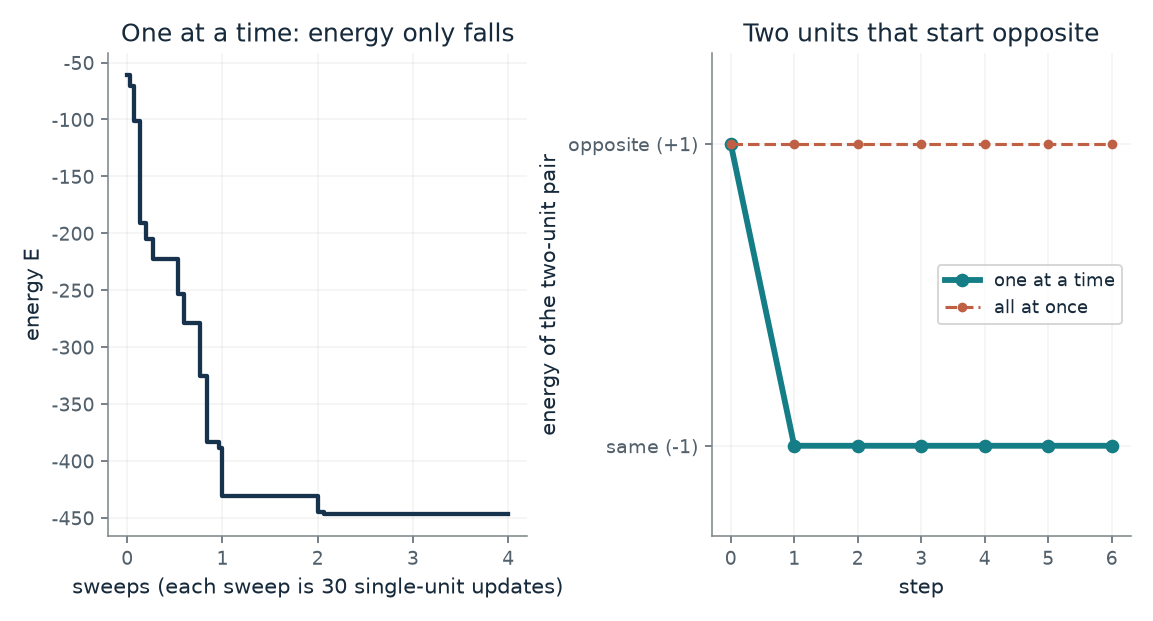

- **Energy at the start:** -61
- **Energy at the end:** -447
- **Largest rise in one step:** 0
- **The run ends in:** a stable state

Updating one unit at a time from random start 1, the energy fell from -61 to -447 and never rose; the largest rise was 0. The two-unit pair on the right settles after one change.

Energy E = -1/2 x sum over i and j of w_ij s_i s_j. For two units joined by a link of 1: matching states give E = -1 and opposite states give E = +1. Updated one at a time from (+1, -1), the first unit sees a vote of -1, becomes -1, and the pair matches with E = -1. Updated together, each copies the other: (+1, -1) becomes (-1, +1) and then back, with E = +1 every step.

In [5]:
figure, values, explanation = energy_picture(**{'schedule': 'one at a time', 'start': 1})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why must units update one at a time?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Update schedule = all at once, Random start number (30 units) = 1: Updated together, the two units each copy the other, swap places, and swap back forever, and their energy stays at plus 1. Updated one at a time they settle immediately and the energy drops to minus 1.

**Takeaway:** One-at-a-time updates cannot raise the energy, so the network must come to rest; simultaneous updates break that guarantee.

**Why it matters:** The energy score is the argument that the network stops. It also explains the difference between a design that is guaranteed to settle and one that merely often does.

**In brains and behavior:** Hopfield used random update moments because there is no evidence for global synchrony among neurons; that is a modeling choice, not a measurement.

**In machines:** A machine that updates all units in parallel can oscillate, so the schedule is part of the algorithm.

**Where it applies:** The guarantee needs three conditions: symmetric links, no self-links, and units updated one at a time with every unit chosen repeatedly. With simultaneous updates the guarantee can fail. The 30-unit runs show behavior in one constructed network.

**Check your understanding:** Two units with a link of 1 are plus and minus. Updating the first alone, what are the states and energy afterwards?

<details><summary>Show the answer</summary>

The first unit hears a vote of -1 from the second and becomes minus one. Both units are minus one, they match, and the energy is -1, down from +1.

</details>

*Source: Chapter 6, Recall slid downhill and stopped, but crowded memories blurred. Book formula and the chapter's own two-unit example (positive link of 1, opposite start). The 30-unit network is a constructed illustration with 5 random patterns (seeds disclosed in the notebook), not Hopfield's runs.*

## C06-D05: How many memories can a network hold?

As more patterns are stored in the same units, when does recall from an exact stored pattern begin to fail?

Every stored memory pulls a little on every vote. With few memories the pulls are small. With many they add up to a hum that can drown the signal. The crosstalk estimate says how likely a unit's first vote is wrong, and the simulation shows what the settling dynamics make of it.

$$
h_i=(N-1)\,\xi_i^{1}+\underbrace{\sum_{\mu\ge 2}\xi_i^{\mu}\sum_{j\ne i}\xi_j^{\mu}\xi_j^{1}}_{\text{crosstalk}},\qquad \Pr(\text{first vote wrong})\approx\Phi\!\left(-\sqrt{\frac{N-1}{P-1}}\right)
$$

**Symbols:** N: the number of units; P: the number of stored patterns; h_i: the total vote on unit i when the network sits on pattern 1; crosstalk: the pull of the other stored patterns, treated as random noise; Phi: the standard bell-curve cumulative probability

**Predict before looking:** With 100 units, predict how recall from an exactly stored pattern changes as the number of stored patterns grows from 5 to 15 and then to 40.

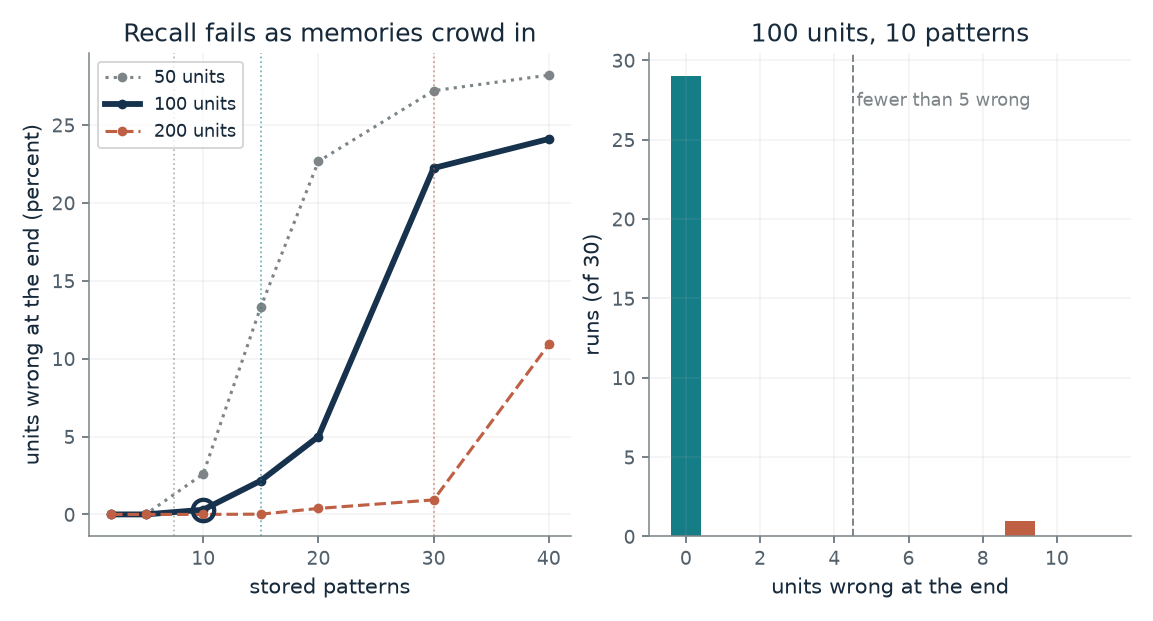

- **Average units wrong at the end:** 0.3
- **Runs with fewer than 5 units wrong:** 29 of 30
- **Runs that stayed exactly at the start:** 29 of 30
- **Share of units wrong after one simultaneous pass (estimate):** 0.046 percent

With 100 units and 10 random patterns, 30 seeded runs started at a stored pattern and ended with 0.3 units wrong on average; 29 of 30 had fewer than 5 wrong. The dotted verticals mark 0.15 N, Hopfield's rule of thumb quoted in the chapter.

Crosstalk estimate: each unit's vote is (N - 1) from its own pattern plus noise of size sqrt((P - 1)(N - 1)). A first-pass error needs the noise to beat the signal: chance = Phi(-sqrt((N - 1)/(P - 1))) = Phi(-sqrt(99/9)) = 0.000456. The runs use the plus/minus-one storage rule and one-at-a-time updates.

In [6]:
figure, values, explanation = capacity_picture(**{'stored': 10, 'units': 100})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How many memories can a network hold?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Stored patterns = 40, Units in the network = 100: At 40 patterns in 100 units, far past the 0.15 N mark at 15, runs from an exactly stored pattern end with many units wrong. With 10 patterns almost every run stays at its start.

**Takeaway:** Every stored pattern adds noise to every vote, and past a point the noise drowns the memory it was meant to protect.

**Why it matters:** A fixed number of units can only keep so many random patterns apart. The limit comes from crosstalk and motivates ways to separate or sharpen memories.

**In brains and behavior:** Hopfield wrote that adding memories past the limit makes all memory states irretrievable unless there is a provision for forgetting old memories. The chapter hands that to the next chapter.

**In machines:** Capacity depends on the coding and the error count. The modern attention-style network's capacity grows much faster, so the 0.15 N rule of thumb does not carry over to it.

**Where it applies:** Random patterns, the unnormalized storage rule, runs that start exactly at a stored pattern, and asynchronous updates. How errors are counted and how units are coded change the capacity figure. Beyond capacity recall can fail outright.

**Check your understanding:** For 100 units and 15 stored patterns, the crosstalk estimate of a wrong first vote per unit is about 0.4 percent. Why can a run still end with many units wrong?

<details><summary>Show the answer</summary>

A few wrong units change the votes that other units hear, and those errors can feed on each other. The estimate describes only the first pass, not the settling that follows.

</details>

*Source: Chapter 6, Recall slid downhill and stopped, but crowded memories blurred. Simulation with disclosed seeds (30 runs per setting) of the plus-or-minus-one network, plus the standard Gaussian crosstalk estimate, which is the companion's own addition and not printed in the chapter. The chapter reports Hopfield's rule of thumb of about 0.15 N for his 0/1 network and his loads of 5 and 15 patterns in 100 units; the counts shown here are this simulation's, not his.*

## C06-D06: What does the sharpness dial do to a best match?

Two stored records match a fragment with scores 3 and 2. How much say does each get, and what does the dial change?

Each stored memory is a voice in a room. A match score says how well it lines up with the cue, and the dial decides how many voices share the result. Turn the dial up and a unique best match takes nearly everything; turn it down and the shares spread out. If two scores tie, they split evenly at any setting.

$$
p_k=\frac{e^{\beta z_k}}{\sum_m e^{\beta z_m}}
$$

**Symbols:** z_k: the match score of stored pattern k; p_k: the share of the say given to pattern k; the shares add to 1; beta: the sharpness setting, above zero; e: the base of natural logarithms, about 2.718

**Predict before looking:** With scores 3 and 2 and the dial at 1, the first record gets about 0.73. Predict its share with the dial at 5, and whether any new evidence has arrived.

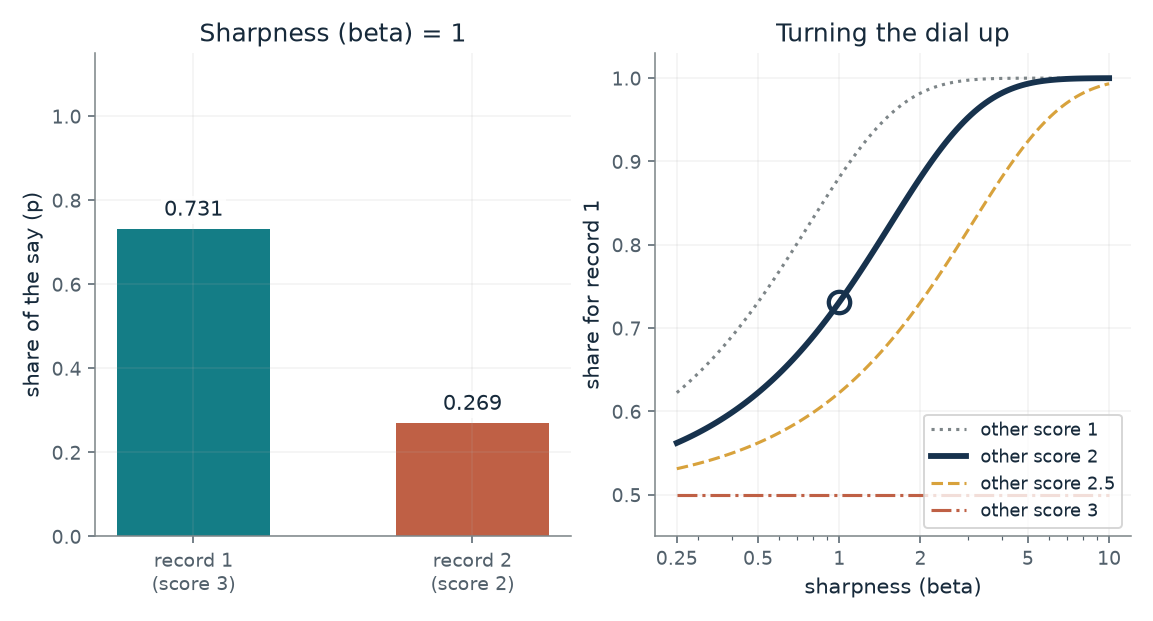

- **Share for record 1:** 0.731
- **Share for record 2:** 0.269
- **Score gap:** 1
- **Shares add up to:** 1

With scores 3 and 2 and beta 1, record 1 gets 0.731 of the say. Nothing about the scores changed, only the dial, and this share is a weight, not the chance that record 1 is right.

p1 = e^(1 x 3) / (e^(1 x 3) + e^(1 x 2)) = 1 / (1 + e^(-1 x 1)) = 0.731. p2 = 1 - p1 = 0.269.

In [7]:
figure, values, explanation = softmax_picture(**{'beta': 1, 'second_score': 2})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What does the sharpness dial do to a best match?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Sharpness (beta) = 5, Score of the other record = 2: At beta 5 the first record gets about 0.99. The scores have not changed and no new evidence has arrived. The larger share is a weight in this calculation, not a 99 percent chance that the first reference is right.

**Takeaway:** Turning the dial up gives a clear best match nearly all the say, without adding any evidence that it is right.

**Why it matters:** The same softmax weights the values in a transformer's attention. The sharpness setting decides whether a lookup picks one stored item or blends several, which matters when a system returns a convincing answer.

**In brains and behavior:** The paper did not test whether biological memory uses this weighting.

**In machines:** In a standard transformer the design fixes the sharpness (beta is 1 over the square root of the key size); here it is a setting that changes how many patterns are averaged.

**Where it applies:** Match scores are given; a tie splits the say evenly at any setting. A share is a weight in this calculation, not a probability that a record is the right one. The intended record may be absent from the candidates, and two records can share the details in the fragment.

**Check your understanding:** Two candidate records tie at score 3. What is each one's share at beta 10, and what would you need before trusting either?

<details><summary>Show the answer</summary>

Each gets 0.5 at any beta, because a tie has no best match. Before trusting either you would need further evidence that separates them, such as the original record.

</details>

*Source: Chapter 6, A sharpness dial let the best match win, and the rule was attention. Book formula (softmax with a sharpness setting, as in Ramsauer and colleagues). The scores 3 and 2 and the settings 1 and 5 are the chapter's made-up illustration; no study measured these scores.*

## C06-D07: How is a memory step the same as an attention step?

If shares come from match scores and the new state is their weighted average, does a sharper dial recall a damaged cue better than a plain vote?

The old network lets every stored memory pull on every vote. The new update gives the best match most of the say. The new state is a weighted average of the stored patterns, with weights from a softmax of the match scores. Read as attention, the cue is the query, the stored patterns are keys and values, and the shares say how much of each value comes back.

$$
\xi^{\text{new}}=\sum_k p_k\,x_k,\qquad p_k=\operatorname{softmax}(\beta z_k),\qquad z_k=x_k^{\top}\xi
$$

$$
\operatorname{attention}(q,K,V)=\operatorname{softmax}\!\bigl(\beta\,Kq\bigr)^{\top}V\quad\text{with }q=\xi,\ K=V=X
$$

**Symbols:** x_k: stored pattern k (a row of X); xi: the current state, the cue; z_k: match score: the entry-by-entry product of x_k and xi, summed; beta: the sharpness dial; q, K, V: query, keys and values; here q is the cue and K and V are the stored patterns

**Predict before looking:** With similar stored patterns, predict whether a gentle dial (beta 0.01) or a sharp one (beta 1) recalls the target better after one step, and how both compare with the plain vote.

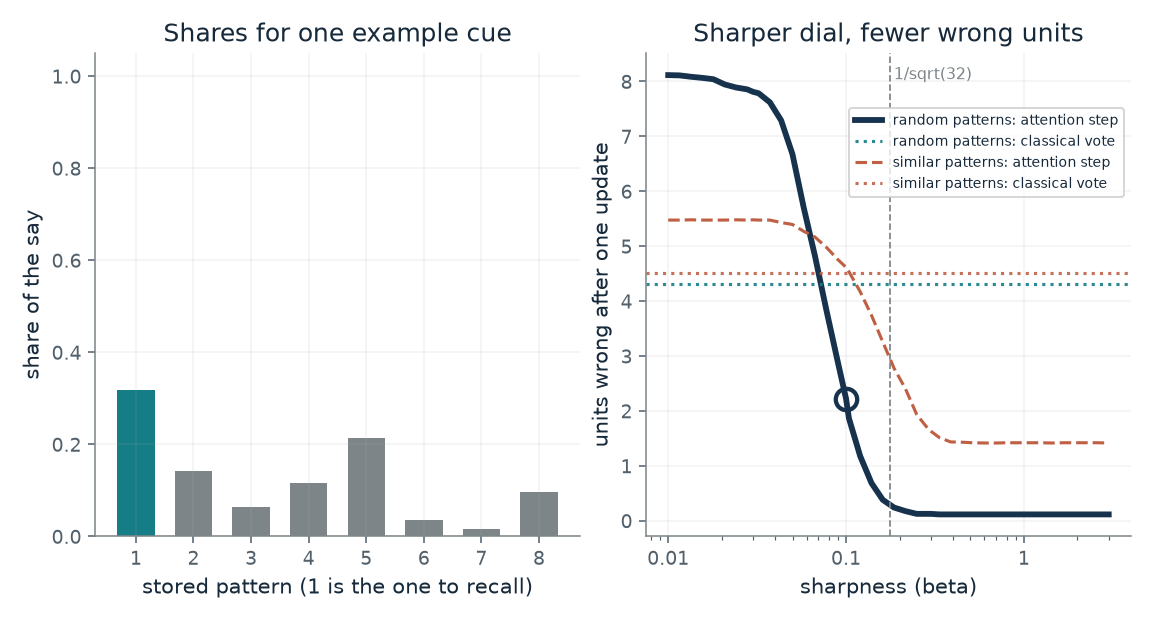

- **Share on the stored pattern (this cue):** 0.317
- **Wrong units after one attention step (200 cues):** 2.23
- **Wrong units after one classical vote step (200 cues):** 4.32
- **Wrong units in the cue:** 8

For random patterns, 32 units and 8 stored patterns, a cue with 8 units wrong gives the right pattern a share of 0.317 at beta 0.1. One attention step leaves 2.23 units wrong on average and one classical vote step leaves 4.32.

Match score z_k = (stored pattern k) . (cue), entry by entry and summed. Shares p_k = e^(beta z_k) / sum of e^(beta z_m). New state = sum of p_k x (stored pattern k), then each entry is read by its sign. The right-hand averages use 200 seeded cues per setting; the dotted horizontal lines are the classical vote step for each kind of pattern. In a transformer, beta is fixed at 1/sqrt(d_k), here about 0.18.

In [8]:
figure, values, explanation = retrieval_picture(**{'beta': 0.1, 'crowding': 'random patterns'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How is a memory step the same as an attention step?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Sharpness (beta) = 1.0, Stored patterns = similar patterns: With a sharp dial the update puts nearly all the say on the closest stored pattern and mostly recovers it, leaving about 1.4 units wrong against 4.5 for the plain vote. A gentle dial returns a blend of the similar patterns, which does worse than the plain vote.

**Takeaway:** A sharp enough dial lets one memory step pick out the best match instead of blending, which is exactly a sharp attention step.

**Why it matters:** This is the link between memory and a transformer's attention: query is the cue, keys and values are what is stored, and the shares decide how much of each stored value comes back.

**In brains and behavior:** The mapping is about a machine update; the paper did not test whether biological memory uses the weighting.

**In machines:** One step of attention and one step of the modern Hopfield update have the same form after projections; they differ in who sets the numbers.

**Where it applies:** The mapping holds for one step. A trained, stacked transformer is not simply a Hopfield memory. Similar patterns are built by flipping 6 of 32 entries of one base pattern, and the cue has 8 wrong units.

**Check your understanding:** If two stored patterns match the cue equally well, what does the update return at any beta?

<details><summary>Show the answer</summary>

An equal blend of the two patterns, because their shares are equal. Entries where the two patterns agree are recovered; entries where they differ average to zero.

</details>

*Source: Chapter 6, A sharpness dial let the best match win, and the rule was attention. Simulation with disclosed seeds (200 cues per setting) of the update rule that Ramsauer and colleagues relate to attention, in the simplified mapping the chapter describes (stored patterns act as both keys and values). The 32-unit random and similar pattern sets are constructed. Not a test of any trained transformer.*

## C06-D08: How much of a preference survives when most cues are removed?

In mice with impaired CA3 plasticity, search in the target quadrant fell from 66.4 to 44.6 percent when three of four cues were removed. What does that say, compared with chance?

With all cues present, both groups spent about two thirds of their search time in the target quadrant, well above the 25 percent that equal search would give. With only one cue left, the knockout mice's share fell to 44.6 percent. Dividing the drop in above-chance preference by the starting preference gives a simple measure of how much survived.

$$
\text{share kept}=\frac{f-25}{b-25}
$$

**Symbols:** b: percent of radial-quadrant time spent in the target quadrant with all cues; f: the same percentage with three of the four cues removed; 25: equal occupancy of the four radial quadrants, in percent

**Predict before looking:** For each group, predict what share of its above-chance preference survives when three of four cues are removed.

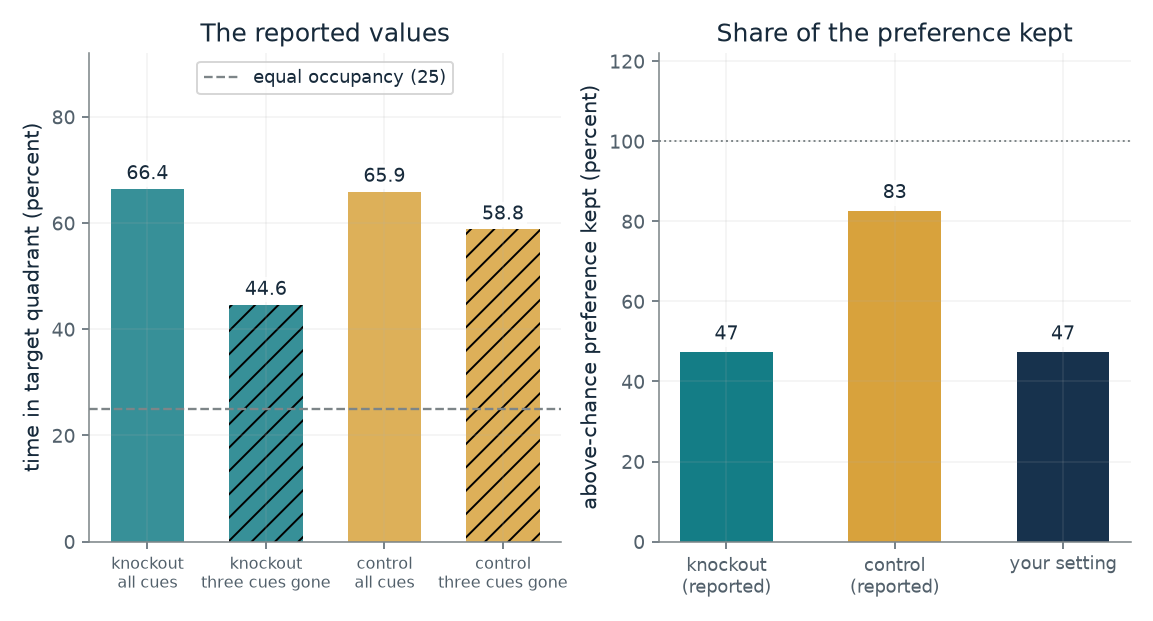

- **Occupancy with all cues:** 66.4 percent
- **Occupancy with the fragment:** 44.6 percent
- **Above-chance preference, all cues to fragment:** 41.4 to 19.6 points
- **Share of that preference kept:** 47 percent

Starting from 66.4 percent, an occupancy of 44.6 percent keeps 47 percent of the preference above the 25 percent equal-occupancy level. The two reported results keep about 47 percent (knockout mice) and 83 percent (controls); the share kept is this companion's own ratio, not a statistic from the study.

Share kept = (44.6 - 25) / (66.4 - 25) = 19.6 / 41.4 = 0.473.

In [9]:
figure, values, explanation = occupancy_picture(**{'fragment': 44.6, 'baseline': 66.4})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How much of a preference survives when most cues are removed?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Occupancy with three cues removed (percent) = 44.6, Occupancy with all cues (percent) = 66.4: The knockout mice keep about 47 percent of their above-chance preference (44.6 against 66.4). The controls keep about 83 percent (58.8 against 65.9). The authors read the knockouts' result as degradation rather than the complete loss of recall.

**Takeaway:** Measured against the 25 percent equal-occupancy level, the knockouts kept roughly half of their preference and the controls most of it.

**Why it matters:** A reported percentage means more when it is read against what chance would give. This is the evidence side of the chapter, and it does not show that a brain follows Hopfield's update rule.

**In brains and behavior:** The study bred mice with impaired NMDA-dependent plasticity in CA3 and tested search with partial cues. It is one behavioral result in one species and says nothing clinical.

**Where it applies:** Occupancy is a behavioral measure of search, not a direct measure of memory strength. The knockouts lacked the receptor subunit both when each memory formed and when it was recalled, and the paper does not separate the two. The result fits a pattern-completion model in a general way and cannot say which update rule CA3 follows. Details of the animals and methods are in the paper, not in this companion.

**Check your understanding:** Why is the share kept not the same as memory strength, and what else would you need to say CA3 does pattern completion?

<details><summary>Show the answer</summary>

Quadrant occupancy depends on how the animal searches, not only on what it remembers, and the knockouts lacked the receptor during both learning and recall. Showing a particular update rule would need a model fitted to the data or a manipulation that separates storage from retrieval.

</details>

*Source: Chapter 6, Mice with impaired CA3 plasticity searched worse from a fragment. Reported values quoted in the chapter from Nakazawa and colleagues (2002): knockout mice 66.4 percent with all cues and 44.6 with a partial cue, control mice 65.9 and 58.8 (the control drop was not statistically significant). The share kept is this companion's own descriptive ratio, not a statistic from the paper. No simulation or model is used here.*

## Bring it to your own question

Ask what is stored, what the cue is, and how similar the stored items are. For a small network, work the vote, the storage sums and the energy by hand before running any simulation. For a retrieval question, compute shares from match scores at the setting actually used and say that a share is a weight, not a chance of being right. Check whether the intended item could be missing from the candidates, and whether two items share the details the cue contains.

Use the `mmi-ch06-remembering-fragment` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.